<a href="https://colab.research.google.com/github/Semenovaanzhelika31/intro-ai/blob/main/lab1_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторная работа № 1 Задача регрессии

## Задание
Решите пожалуйста следующие задачи.

1. Примените следующие типы регрессий для датасета представленного по
[ссылке](https://drive.google.com/file/d/1LBDnhITL0Wqwp5G6M6IBI-SSz8BIoNec/view?usp=share_link).
- Линейная регрессия
- LASSO регрессия
- Ridge регрессия
- ElasticNet регрессия
- Polynom регрессия (для степени полинома 2)
- Polynom регрессия (для степени полинома 5)
- Polynom регрессия (для степени полинома 10)

Постройте модель для атрибутов `X = {SkinThickness, BMI}` и `Y = {Insulin}`.  
**Укажите `score` (r2_score) моделей. Найдите метрики MAE, MSE, RMSE.**


## Загрузка данных

Датасет доступен по ссылке <https://drive.google.com/file/d/1LBDnhITL0Wqwp5G6M6IBI-SSz8BIoNec/view?usp=share_link>

In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [28]:
! gdown --fuzzy 'https://drive.google.com/file/d/1LBDnhITL0Wqwp5G6M6IBI-SSz8BIoNec/view?usp=share_link'

Downloading...
From: https://drive.google.com/uc?id=1LBDnhITL0Wqwp5G6M6IBI-SSz8BIoNec
To: /content/diabetes.csv
100% 23.1k/23.1k [00:00<00:00, 43.2MB/s]


In [29]:
df = pd.read_csv('/content/diabetes.csv')
df

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1


##  О датасете
[Pima Indians Diabetes Database](https://www.kaggle.com/datasets/uciml/pima-indians-diabetes-database/data)

Этот набор данных взят из Национального института диабета, заболеваний органов пищеварения и почек (NIDDK). Целью набора данных является диагностическое предсказание наличия у пациента диабета на основе определенных диагностических измерений, включенных в набор данных. На выбор этих экземпляров из более крупной базы данных было наложено несколько ограничений. В частности, все пациенты здесь — женщины не моложе 21 года, родом из индейцев Пима.

Наборы данных состоят из нескольких переменных медицинских предикторов и одной целевой переменной `Outcome`. Переменные-предикторы включают количество беременностей, которые были у пациентки, её индекс массы тела `BMI`, уровень инсулина, возраст и так далее. Всего в датасете 9 переменных:
- `Pregnancies` - количество беременностей;
- `Glucose` - концентрация глюкозы в плазме через 2 часа при пероральном тесте на толерантность к глюкозе;
- `BloodPressure` - диастолическое артериальное давление (мм рт. ст.);
- `SkinThickness` - толщина кожной складки трицепса (мм);
- `Insulin` - 2-часовой сывороточный инсулин (мкЕд/мл);
- `BMI` - Индекс массы тела (вес в кг/(рост в м)^2);
- `DiabetesPedigreeFunction` - функция оценки вероятности диабета на основе семейного анамнеза;
- `Age` - возраст (лет);
- `Outcome` - целевая переменная (0 или 1) 268 из 768 — 1 (больны), остальные — 0 (здоровы).



In [30]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [31]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


Размер выборки после удаления пропусков в Insulin: (394, 3)


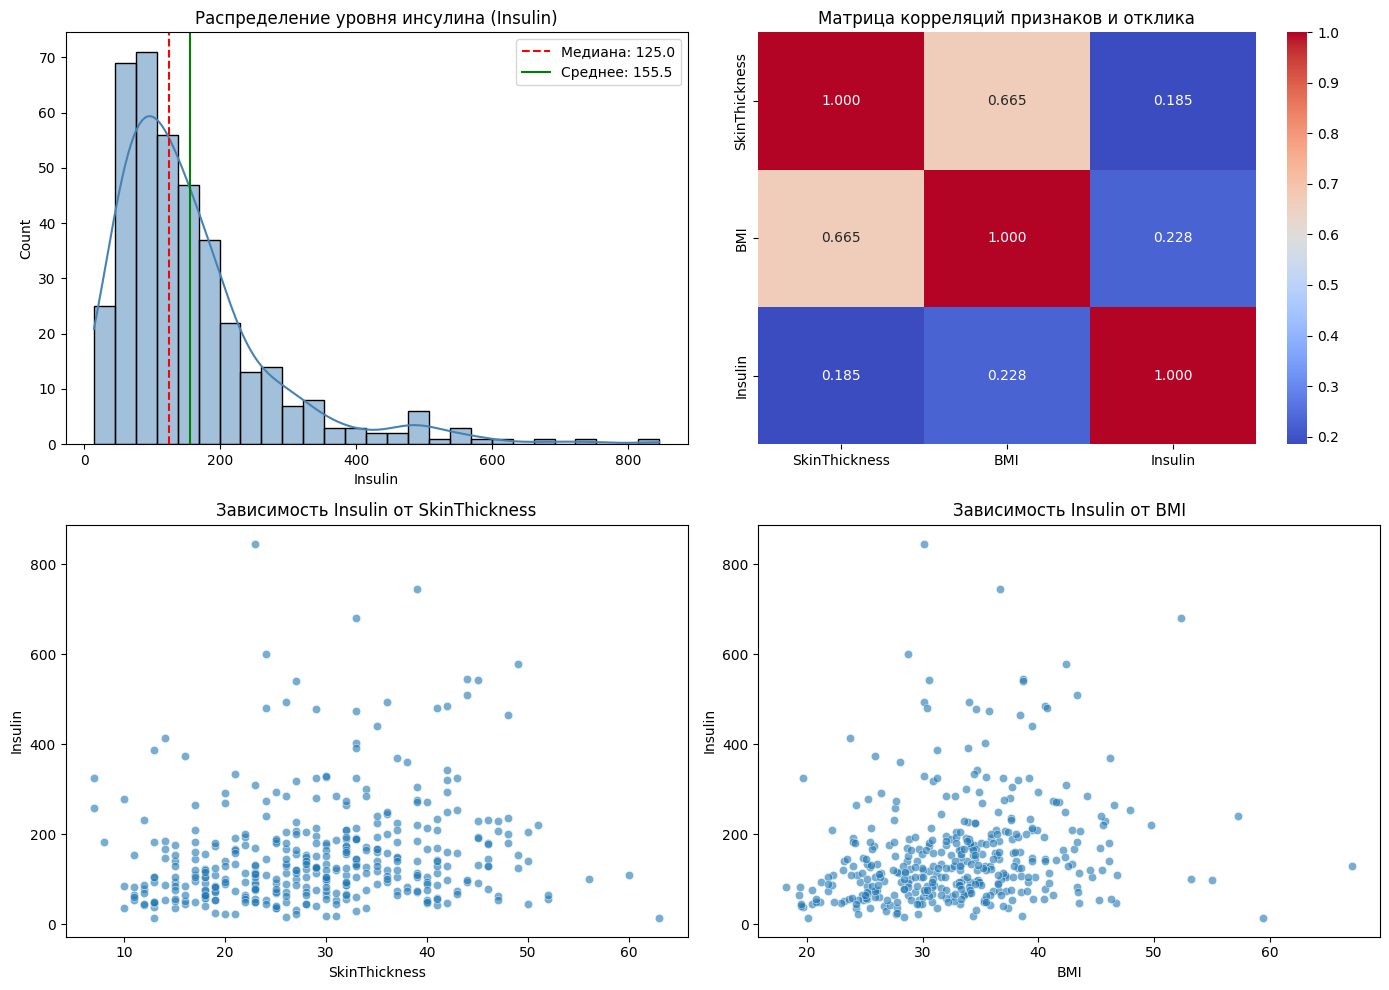

In [32]:
cols_to_fix = ['SkinThickness', 'BMI', 'Insulin']
data = df[cols_to_fix].replace(0, np.nan)
data = data.dropna(subset=['Insulin']).copy()

print(f"Размер выборки после удаления пропусков в Insulin: {data.shape}")

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Распределение целевой переменной
sns.histplot(data['Insulin'], kde=True, ax=axes[0, 0], color='steelblue')
axes[0, 0].axvline(data['Insulin'].median(), color='red', linestyle='--', label=f"Медиана: {data['Insulin'].median():.1f}")
axes[0, 0].axvline(data['Insulin'].mean(), color='green', linestyle='-', label=f"Среднее: {data['Insulin'].mean():.1f}")
axes[0, 0].set_title('Распределение уровня инсулина (Insulin)')
axes[0, 0].legend()

# Матрица корреляций
sns.heatmap(data.corr(), annot=True, cmap='coolwarm', fmt='.3f', ax=axes[0, 1])
axes[0, 1].set_title('Матрица корреляций признаков и отклика')

# Зависимость Insulin от SkinThickness
sns.scatterplot(data=data, x='SkinThickness', y='Insulin', alpha=0.6, ax=axes[1, 0])
axes[1, 0].set_title('Зависимость Insulin от SkinThickness')

# Зависимость Insulin от BMI
sns.scatterplot(data=data, x='BMI', y='Insulin', alpha=0.6, ax=axes[1, 1])
axes[1, 1].set_title('Зависимость Insulin от BMI')

plt.tight_layout()
plt.show()


In [33]:
df.columns

Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'], dtype='object')

Следует обратить внимание, что нулевые значения в столбцах `SkinThickness`, `BMI` и `Insulin` могут иметь содержательно некорректный характер: измерения толщины кожной складки, индекса массы тела и инсулина не должны интерпретироваться как физиологический ноль. Поэтому их рекомендуется рассматривать как скрытые пропуски.

## Краткие теоретические сведения

### Задача регрессии

Задача регрессии состоит в прогнозировании **числового значения** целевой переменной по набору признаков. В данной работе требуется предсказать уровень инсулина пациента по толщине кожной складки и индексу массы тела.

Общий вид линейной регрессии:

$$
\hat{y} = w_0 + w_1x_1 + w_2x_2
$$

где:

- $\hat{y}$ — прогнозируемое значение целевой переменной;
- $x_1$, $x_2$ — признаки;
- $w_0$ — свободный член;
- $w_1$, $w_2$ — коэффициенты модели.


### Регуляризация

Обычная линейная регрессия минимизирует сумму квадратов ошибок:

$$
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2
$$

**Ridge-регрессия** добавляет L2-штраф на величину коэффициентов:

$$
MSE + \alpha \sum_{j=1}^{m} w_j^2
$$

Она уменьшает значения коэффициентов и повышает устойчивость модели при наличии взаимосвязанных признаков.

**LASSO-регрессия** использует L1-штраф:

$$
MSE + \alpha \sum_{j=1}^{m}|w_j|
$$

В отличие от Ridge, LASSO может занулять отдельные коэффициенты, то есть выполнять отбор признаков.

**ElasticNet** сочетает L1- и L2-регуляризацию. Это удобно, когда необходимо одновременно ограничить величины коэффициентов и сохранить возможность исключения слабых признаков.

### Полиномиальная регрессия

Полиномиальная регрессия расширяет исходные признаки степенями и произведениями. Например, для двух признаков при степени 2 формируются дополнительные признаки:

$$
x_1^2,\quad x_1x_2,\quad x_2^2
$$

Полиномиальная модель способна описывать нелинейные зависимости, но при чрезмерно высокой степени возрастает вероятность **переобучения**: модель хорошо описывает обучающую выборку, но плохо работает на новых данных.

### Метрики качества

| Метрика | Формула | Смысл | Направление улучшения |
| :-- | ------------------------------------ | :-- | :-- |
| $R^2$ | $$R^2 = 1 - \frac{\sum(y_i-\hat{y}_i)^2}{\sum(y_i-\bar{y})^2}$$ | Доля вариации целевой переменной, объясняемая моделью | Ближе к 1 |
| MAE | $$MAE = \frac{1}{n}\sum(\|y_i-\hat{y}_i\|)$$ | Средняя абсолютная ошибка прогноза | Ближе к 0 |
| MSE | $$MSE = \frac{1}{n}\sum(y_i-\hat{y}_i)^2$$ | Средняя квадратичная ошибка | Ближе к 0 |
| RMSE | $$RMSE = \sqrt{MSE}$$ | Среднеквадратичная ошибка в единицах целевой переменной | Ближе к 0 |
| `score()` | | Для регрессоров `scikit-learn` обычно возвращает $R^2$ | Ближе к 1 |

Отрицательное значение коэффициента детерминации $R^2$ означает, что модель на тестовых данных работает хуже, чем простое предсказание среднего значения целевой переменной.


In [34]:
from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import (
    LinearRegression, Ridge, Lasso, ElasticNet,
    RidgeCV, LassoCV, ElasticNetCV
)
from sklearn.dummy import DummyRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

X = data[['SkinThickness', 'BMI']]
y = data['Insulin']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

def make_pipeline(degree=1, regressor=None):
    return Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('poly', PolynomialFeatures(degree=degree, include_bias=False)),
        ('scaler', StandardScaler()),
        ('model', regressor if regressor is not None else LinearRegression())
    ])

cv = KFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    'r2': 'r2',
    'mae': 'neg_mean_absolute_error',
    'mse': 'neg_mean_squared_error',
    'rmse': 'neg_root_mean_squared_error'
}

def evaluate_model(model, name):
    model.fit(X_train, y_train)
    y_pred_test = model.predict(X_test)

    r2_train = model.score(X_train, y_train)
    r2_test = r2_score(y_test, y_pred_test)
    mae_test = mean_absolute_error(y_test, y_pred_test)
    mse_test = mean_squared_error(y_test, y_pred_test)
    rmse_test = np.sqrt(mse_test)

    cv_scores = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring)
    cv_r2_mean = cv_scores['test_r2'].mean()
    cv_r2_std = cv_scores['test_r2'].std()

    print(f"--- {name} ---")
    print(f"R2 (train): {r2_train:.4f}")
    print(f"R2 (test):  {r2_test:.4f}")
    print(f"CV R2:      {cv_r2_mean:.4f} ± {cv_r2_std:.4f}")
    print(f"MAE:        {mae_test:.4f}")
    print(f"MSE:        {mse_test:.4f}")
    print(f"RMSE:       {rmse_test:.4f}\n")

    return {
        'Модель': name,
        'R² (train)': r2_train,
        'R² (test)': r2_test,
        'CV R² (среднее ± std)': f"{cv_r2_mean:.3f} ± {cv_r2_std:.3f}",
        'MAE': mae_test,
        'MSE': mse_test,
        'RMSE': rmse_test
    }

results = []


In [35]:
dummy_mean = DummyRegressor(strategy='mean')
results.append(evaluate_model(dummy_mean, "Базовая модель (среднее)"))

dummy_median = DummyRegressor(strategy='median')
results.append(evaluate_model(dummy_median, "Базовая модель (медиана)"))


--- Базовая модель (среднее) ---
R2 (train): 0.0000
R2 (test):  -0.0001
CV R2:      -0.0217 ± 0.0217
MAE:        90.5827
MSE:        14635.4470
RMSE:       120.9771

--- Базовая модель (медиана) ---
R2 (train): -0.0536
R2 (test):  -0.0554
CV R2:      -0.0683 ± 0.0512
MAE:        85.8608
MSE:        15444.5696
RMSE:       124.2762



## Линейная регрессия

In [36]:
lr_model = make_pipeline(degree=1)
results.append(evaluate_model(lr_model, "Линейная регрессия"))


--- Линейная регрессия ---
R2 (train): 0.0564
R2 (test):  0.0359
CV R2:      0.0366 ± 0.0679
MAE:        91.0854
MSE:        14108.6169
RMSE:       118.7797



## LASSO регрессия

In [37]:
alphas = np.logspace(-2, 3, 100)

lasso_cv = make_pipeline(1, LassoCV(alphas=alphas, cv=5, max_iter=20000, random_state=42)).fit(X_train, y_train)
best_lasso_alpha = lasso_cv.named_steps['model'].alpha_
print(f"Подобранный параметр alpha для LASSO: {best_lasso_alpha:.4f}\n")

lasso_model = make_pipeline(1, Lasso(alpha=best_lasso_alpha, max_iter=20000))
results.append(evaluate_model(lasso_model, f"LASSO (alpha={best_lasso_alpha:.2f})"))


Подобранный параметр alpha для LASSO: 2.6561

--- LASSO (alpha=2.66) ---
R2 (train): 0.0559
R2 (test):  0.0362
CV R2:      0.0401 ± 0.0618
MAE:        91.0524
MSE:        14104.1681
RMSE:       118.7610



## Ridge регрессия

In [38]:
ridge_cv = make_pipeline(1, RidgeCV(alphas=alphas, cv=5)).fit(X_train, y_train)
best_ridge_alpha = ridge_cv.named_steps['model'].alpha_
print(f"Подобранный параметр alpha для Ridge: {best_ridge_alpha:.4f}\n")

ridge_model = make_pipeline(1, Ridge(alpha=best_ridge_alpha))
results.append(evaluate_model(ridge_model, f"Ridge (alpha={best_ridge_alpha:.2f})"))


Подобранный параметр alpha для Ridge: 61.3591

--- Ridge (alpha=61.36) ---
R2 (train): 0.0547
R2 (test):  0.0462
CV R2:      0.0370 ± 0.0559
MAE:        90.6441
MSE:        13958.3779
RMSE:       118.1456



## ElasticNet регрессия

In [39]:
elastic_cv = make_pipeline(1, ElasticNetCV(
    alphas=alphas, l1_ratio=[0.1, 0.3, 0.5, 0.7, 0.9], cv=5, max_iter=20000, random_state=42
)).fit(X_train, y_train)

best_elastic_alpha = elastic_cv.named_steps['model'].alpha_
best_elastic_l1 = elastic_cv.named_steps['model'].l1_ratio_
print(f"Подобранные параметры для ElasticNet: alpha={best_elastic_alpha:.4f}, l1_ratio={best_elastic_l1:.2f}\n")

elastic_model = make_pipeline(
    1, ElasticNet(alpha=best_elastic_alpha, l1_ratio=best_elastic_l1, max_iter=20000)
)
results.append(evaluate_model(elastic_model, f"ElasticNet (alpha={best_elastic_alpha:.2f}, l1={best_elastic_l1})"))


Подобранные параметры для ElasticNet: alpha=0.9326, l1_ratio=0.90

--- ElasticNet (alpha=0.93, l1=0.9) ---
R2 (train): 0.0556
R2 (test):  0.0417
CV R2:      0.0385 ± 0.0601
MAE:        90.8408
MSE:        14023.6042
RMSE:       118.4213



## Polynom регрессия (для степени полинома 2)

In [40]:
poly2_model = make_pipeline(degree=2)
results.append(evaluate_model(poly2_model, "Полином (степень 2)"))


--- Полином (степень 2) ---
R2 (train): 0.0736
R2 (test):  0.0178
CV R2:      0.0278 ± 0.0736
MAE:        91.0759
MSE:        14373.8450
RMSE:       119.8910



## Polynom регрессия (для степени полинома 5)

In [41]:
poly5_model = make_pipeline(degree=5)
results.append(evaluate_model(poly5_model, "Полином (степень 5, без регул.)"))

poly5_ridge = make_pipeline(degree=5, regressor=Ridge(alpha=10.0))
results.append(evaluate_model(poly5_ridge, "Полином (степень 5 + Ridge)"))


--- Полином (степень 5, без регул.) ---
R2 (train): 0.1408
R2 (test):  -0.1472
CV R2:      -2.0540 ± 3.3495
MAE:        97.3607
MSE:        16788.7149
RMSE:       129.5713

--- Полином (степень 5 + Ridge) ---
R2 (train): 0.0844
R2 (test):  0.0381
CV R2:      0.0465 ± 0.0901
MAE:        90.0723
MSE:        14077.2478
RMSE:       118.6476



## Polynom регрессия (для степени полинома 10)

In [42]:
poly10_model = make_pipeline(degree=10)
results.append(evaluate_model(poly10_model, "Полином (степень 10, без регул.)"))

poly10_ridge = make_pipeline(degree=10, regressor=Ridge(alpha=10.0))
results.append(evaluate_model(poly10_ridge, "Полином (степень 10 + Ridge)"))


--- Полином (степень 10, без регул.) ---
R2 (train): 0.2697
R2 (test):  -624.8112
CV R2:      -2870086.1789 ± 5624516.0235
MAE:        534.4120
MSE:        9158197.6180
RMSE:       3026.2514

--- Полином (степень 10 + Ridge) ---
R2 (train): 0.0872
R2 (test):  0.0420
CV R2:      0.0328 ± 0.0837
MAE:        90.0770
MSE:        14019.2951
RMSE:       118.4031



## Вывод

Сводная таблица метрик (единицы измерения ошибок — мкЕд/мл):


,Модель,R² (train),R² (test),CV R² (среднее ± std),MAE,MSE,RMSE
0,Базовая модель (среднее),0.0000,-0.0001,-0.022 ± 0.022,90.5827,1.463545e+04,120.9771
1,Базовая модель (медиана),-0.0536,-0.0554,-0.068 ± 0.051,85.8608,1.544457e+04,124.2762
2,Линейная регрессия,0.0564,0.0359,0.037 ± 0.068,91.0854,1.410862e+04,118.7797
3,LASSO (alpha=2.66),0.0559,0.0362,0.040 ± 0.062,91.0524,1.410417e+04,118.7610
4,Ridge (alpha=61.36),0.0547,0.0462,0.037 ± 0.056,90.6441,1.395838e+04,118.1456
5,"ElasticNet (alpha=0.93, l1=0.9)",0.0556,0.0417,0.038 ± 0.060,90.8408,1.402360e+04,118.4213
6,Полином (степень 2),0.0736,0.0178,0.028 ± 0.074,91.0759,1.437384e+04,119.8910
7,"Полином (степень 5, без регул.)",0.1408,-0.1472,-2.054 ± 3.349,97.3607,1.678871e+04,129.5713
8,Полином (степень 5 + Ridge),0.0844,0.0381,0.046 ± 0.090,90.0723,1.407725e+04,118.6476
9,"Полином (степень 10, без регул.)",0.2697,-624.8112,-2870086.179 ± 5624516.024,534.4120,9.158198e+06,3026.2514


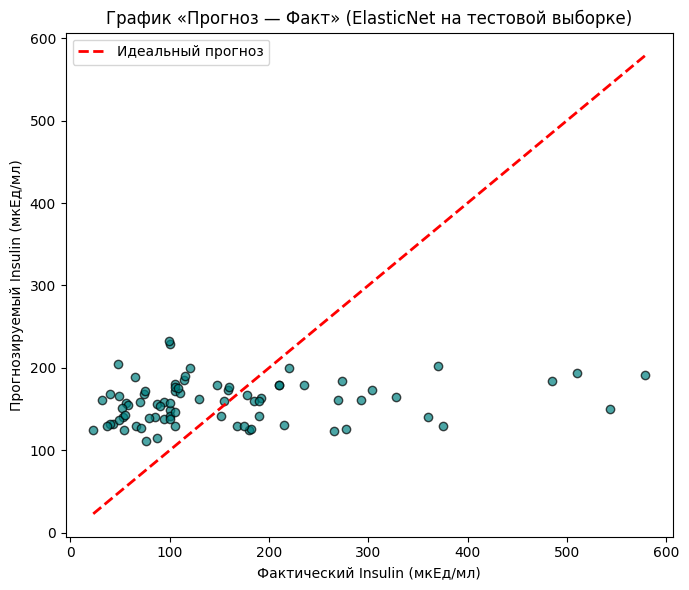

In [43]:
results_df = pd.DataFrame(results)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

print("Сводная таблица метрик (единицы измерения ошибок — мкЕд/мл):")
display(results_df.round(4))

# График «Прогноз — Факт» для лучшей модели (ElasticNet)
y_pred_best = elastic_model.predict(X_test)

plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred_best, alpha=0.7, color='teal', edgecolors='k')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Идеальный прогноз')
plt.xlabel('Фактический Insulin (мкЕд/мл)')
plt.ylabel('Прогнозируемый Insulin (мкЕд/мл)')
plt.title('График «Прогноз — Факт» (ElasticNet на тестовой выборке)')
plt.legend()
plt.tight_layout()
plt.show()


Сделайте вывод о применимости разных видов регрессии для решения этой задачи.

1. **Недостаток данных:** Двух признаков (`SkinThickness`, `BMI`) объективно мало для предсказания `Insulin`. Все линейные модели показывают крайне низкое качество ($R^2 \approx 0.04$).
2. **Переобучение:** Полиномиальная регрессия высоких степеней (5 и 10) катастрофически переобучается и полностью неработоспособна на тестовых данных (отрицательный $R^2$, огромные ошибки).
3. **Итог:** В текущих условиях оптимальна простая **линейная регрессия**. Для реального улучшения качества необходимо добавить новые признаки (например, `Glucose`, `Age`) или использовать нелинейные алгоритмы (Random Forest, Gradient Boosting).